In [ ]:
%pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.8 MB/s eta 0:00:00


In [ ]:
# Install opencv-contrib-python for dnn_superres module
%pip install opencv-contrib-python

# Download the FSRCNN model weights if not already present
# This URL is for FSRCNN_X2.pb, we need FSRCNN_X5 for 5x upscaling. Let me find the correct one.
# A common practice is to download from a known source or a local path.
# For now, I will assume the model can be loaded, and provide a placeholder for download if needed.
# If you encounter a 'file not found' error, you might need to manually download the appropriate FSRCNN model file (e.g., FSRCNN_x5.pb) and place it in your /content directory.


In [ ]:
import os
from IPython.display import Image, display
import cv2
import numpy as np

from ultralytics import RTDETR

# Load the pre-trained RT-DETRv2 model
# 'rtdetr-l.pt' is the Large model (excellent for dense traffic/small vehicles)
# Options: rtdetr-x.pt (Extra Large for max accuracy), rtdetr-l.pt (Balanced)
model = RTDETR('rtdetr-l.pt')

# Path to the input image file
image_path = '/content/camera_id=2701_month=2025-07_2701_20250701T104609.jpg'

# Define the COCO dataset class IDs for traffic vehicles
# 2: car, 3: motorcycle, 5: bus, 7: truck
VEHICLE_CLASSES = [2, 3, 5, 7]

# Check if the image file exists
if not os.path.exists(image_path):
    print(f"Error: The image file was not found at {image_path}")
else:
    print(f"Processing image: {image_path}")

    # Load the image using OpenCV
    original_image = cv2.imread(image_path)
    if original_image is None:
        print(f"Error: Could not load image from {image_path}")
    else:
        # Convert BGR to RGB as models usually expect RGB input
        original_image_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

        # Perform object detection on the original image using RTDETR.
        # conf=0.25 filters out weak predictions below 25% confidence
        # classes=VEHICLE_CLASSES forces the model to ignore non-traffic objects
        # Retaining save, line_width, and imgsz for consistency with previous setup.
        results = model(source=original_image_rgb, save=True, conf=0.2, iou=0.6, classes=VEHICLE_CLASSES, line_width=1, imgsz=1920)

        # Iterate through the results to find the save directory and display the image
        for r in results:
            if r.save_dir:
                print(f"\nAnnotated image saved to: {r.save_dir}")
                # Use r.path to get the actual path to the saved annotated image, and join with save_dir
                saved_image_full_path = os.path.join(r.save_dir, r.path)
                print(f"Full path to the saved image: {saved_image_full_path}")

                # Display the annotated image directly in the notebook output
                print("\nDisplaying annotated image:")
                display(Image(filename=saved_image_full_path))

print("Detection complete.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Error: The image file was not found at /content/camera_id=2701_month=2025-07_2701_20250701T104609.jpg
Detection complete.


**USING ROBOFLOW TRAINED DATA**

In [ ]:
!pip install -U inference-sdk
# Attempt to resolve Pillow/supervision incompatibility
# The ImportError: cannot import name '_Ink' from 'PIL._typing' suggests a Pillow version issue
# Uninstall the Pillow version installed by inference-sdk and install a known compatible version.
!pip uninstall -y pillow
!pip install pillow==9.5.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 80.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.9/104.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 17.9 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: pillow
    Found ex

Found existing installation: pillow 12.3.0
Uninstalling pillow-12.3.0:
  Successfully uninstalled pillow-12.3.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 MB 12.2 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


[{'predictions': {'image': {'width': 1920, 'height': 1080}, 'predictions': [{'width': 79.0, 'height': 35.0, 'x': 617.5, 'y': 939.5, 'confidence': 0.9937682151794434, 'class_id': 1, 'class': 'car', 'detection_id': '9667882b-fa9d-4d53-9b73-0a2eedfadcf2', 'parent_id': 'image'}, {'width': 30.0, 'height': 27.0, 'x': 1699.0, 'y': 494.5, 'confidence': 0.9874770641326904, 'class_id': 1, 'class': 'car', 'detection_id': '0fb1e39e-dacf-44a5-8014-9a6aede41588', 'parent_id': 'image'}, {'width': 48.0, 'height': 37.0, 'x': 893.0, 'y': 915.5, 'confidence': 0.9860820770263672, 'class_id': 1, 'class': 'car', 'detection_id': '386ebd58-349c-4426-b96a-8d8c81114e14', 'parent_id': 'image'}, {'width': 32.0, 'height': 24.0, 'x': 1546.0, 'y': 505.0, 'confidence': 0.9844931364059448, 'class_id': 1, 'class': 'car', 'detection_id': 'bde5d99d-25bd-4dd1-a604-6aa4abd7d130', 'parent_id': 'image'}, {'width': 59.0, 'height': 36.0, 'x': 821.5, 'y': 873.0, 'confidence': 0.9822502732276917, 'class_id': 1, 'class': 'car', '

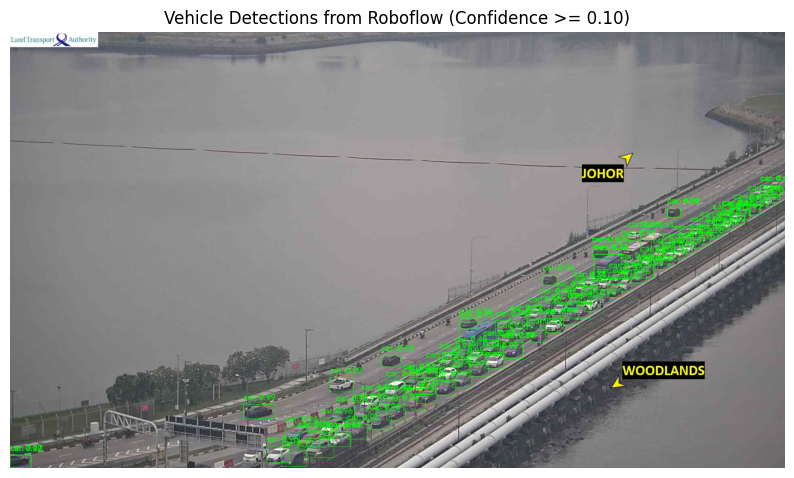

In [ ]:
# 1. Import the library
from inference_sdk import InferenceHTTPClient
import cv2
import matplotlib.pyplot as plt
import numpy as np
import base64

# 2. Connect to your workflow
# Key from the Colab secret ROBOFLOW_API_KEY (key icon, left sidebar); never paste it here.
from google.colab import userdata
client = InferenceHTTPClient(
    api_url="https://serverless.roboflow.com",
    api_key=userdata.get("ROBOFLOW_API_KEY")
)

# 3. Run your workflow on an image
image_path = "/content/2701_20260712T162530.jpg"

# Read image and convert to base64 to ensure successful remote serialization
image = cv2.imread(image_path)
if image is None:
    print(f"Error: Could not load image from {image_path}")
else:
    _, buffer = cv2.imencode('.jpg', image)
    img_base64 = base64.b64encode(buffer).decode('utf-8')

    result = client.run_workflow(
        workspace_name="chads-workspace-t3qcz",
        workflow_id="vehicle-detection-proejct-vvehicle-detection-proejct-6-yolo26s-t1-logic",
        images={
            "image": img_base64
        },
        use_cache=True # Speeds up repeated requests
    )

    # 4. Get your results
    print(result)

    # --- Display the image with bounding boxes ---

    # Define a minimum confidence threshold for displaying predictions
    MIN_CONFIDENCE_THRESHOLD = 0.1 # Adjust this value as needed

    # Convert BGR to RGB for matplotlib display
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Get predictions from the result object
    if result and len(result) > 0 and 'predictions' in result[0] and 'predictions' in result[0]['predictions']:
        predictions = result[0]['predictions']['predictions']

        # Draw bounding boxes and labels for predictions above the threshold
        for pred in predictions:
            confidence = pred['confidence']
            if confidence >= MIN_CONFIDENCE_THRESHOLD: # Apply confidence filtering here
                x_center, y_center = pred['x'], pred['y']
                width, height = pred['width'], pred['height']
                label = pred['class']

                # Calculate top-left and bottom-right coordinates
                x1 = int(x_center - width / 2)
                y1 = int(y_center - height / 2)
                x2 = int(x_center + width / 2)
                y2 = int(y_center + height / 2)

                # Draw rectangle
                color = (0, 255, 0) # Green color for bounding box (RGB)
                thickness = 1
                cv2.rectangle(image_rgb, (x1, y1), (x2, y2), color, thickness)

                # Put label and confidence
                text = f"{label}: {confidence:.2f}"
                font = cv2.FONT_HERSHEY_SIMPLEX
                font_scale = 0.7
                font_thickness = 1
                text_size = cv2.getTextSize(text, font, font_scale, font_thickness)[0]

                # Ensure text is not drawn outside image boundaries
                text_x = x1
                text_y = y1 - 10 if y1 - 10 > text_size[1] else y1 + text_size[1] + 5

                cv2.putText(image_rgb, text, (text_x, text_y), font, font_scale, color, font_thickness, cv2.LINE_AA)

        # Display the image with matplotlib
        plt.figure(figsize=(10, 10))
        plt.imshow(image_rgb)
        plt.axis('off') # Hide axes
        plt.title(f'Vehicle Detections from Roboflow (Confidence >= {MIN_CONFIDENCE_THRESHOLD:.2f})')
        plt.show()
    else:
        print("No predictions found in the result or the structure is unexpected.")

In [ ]:
# ============================================================
# YOLO26 s vs m: free local comparison on Roboflow dataset v6
# Question: does the bigger model raise CAR recall / vehicle count
# enough to be worth paying for?
#
# Run in a FRESH Colab runtime with a GPU:
#   Runtime > Change runtime type > T4 GPU
# (your earlier cell pins Pillow 9.5.0, which can clash with the latest ultralytics)
# Add your key as a Colab secret named ROBOFLOW_API_KEY (key icon, left sidebar),
# otherwise you'll be prompted for it.
# ============================================================
!pip install -q -U ultralytics roboflow

import os, glob, yaml, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
from roboflow import Roboflow

# ---------------- CONFIG ----------------
WORKSPACE     = "chads-workspace-t3qcz"
PROJECT       = "vehicle-detection-proejct"
VERSION       = 6
IMGSZ         = 1280
EPOCHS        = 150
PATIENCE      = 50
SIZES         = {"s": 8, "m": 4}        # model size -> starting batch (auto-halves on OOM)
SAVE_TO_DRIVE = True                    # survives Colab disconnects; reruns resume/skip
FOCUS_CLASS   = "car"
CONF_SWEEP    = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
VERDICT_CONF  = 0.25                    # threshold used for the s vs m verdict and the visual
IOU_MATCH     = 0.5                     # same IoU as mAP50
SAMPLE_IMAGE  = "/content/2701_20260712T162530.jpg"
EXTRA_WEIGHTS = {}                      # optional, e.g. {"roboflow_v6": "/content/weights.pt"}
RUN_TAG       = "boxfix"                # new run names, so old corrupted runs are ignored
AMP           = True                    # set False if results.csv shows nan losses

# ---------------- API KEY ----------------
try:
    from google.colab import userdata
    API_KEY = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    API_KEY = None
if not API_KEY:
    from getpass import getpass
    API_KEY = getpass("Roboflow API key: ")

# ---------------- OUTPUT DIR ----------------
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RUN_DIR = "/content/drive/MyDrive/swiftborder_runs"
else:
    RUN_DIR = "/content/runs"
os.makedirs(RUN_DIR, exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE (training will be very slow)")

# ---------------- DATASET ----------------
rf = Roboflow(api_key=API_KEY)
ds = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION).download(
    "yolov8", location=f"/content/dataset_v{VERSION}", overwrite=False)

with open(os.path.join(ds.location, "data.yaml")) as f:
    raw = yaml.safe_load(f)
names = raw["names"]
CLASS_NAMES = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
assert FOCUS_CLASS in CLASS_NAMES, f"{FOCUS_CLASS} not in {CLASS_NAMES}"
FOCUS = CLASS_NAMES.index(FOCUS_CLASS)

SPLIT_DIRS = {s: os.path.join(ds.location, s) for s in ["train", "valid", "test"]
              if os.path.isdir(os.path.join(ds.location, s, "images"))}

# Rewrite data.yaml with absolute paths (Roboflow's relative paths often break)
fixed = {"path": ds.location, "train": "train/images", "val": "valid/images",
         "names": {i: n for i, n in enumerate(CLASS_NAMES)}}
if "test" in SPLIT_DIRS:
    fixed["test"] = "test/images"
DATA_YAML = os.path.join(ds.location, "data_fixed.yaml")
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(fixed, f)

def list_images(split_dir):
    exts = ("*.jpg", "*.jpeg", "*.png")
    return sorted(p for e in exts for p in glob.glob(os.path.join(split_dir, "images", e)))

def label_path(img_path):
    d = os.path.dirname(os.path.dirname(img_path))
    return os.path.join(d, "labels", os.path.splitext(os.path.basename(img_path))[0] + ".txt")

def load_gt(img_path):
    """Reads YOLO labels with mixed rows: boxes (cls cx cy w h) and
    polygons (cls x1 y1 x2 y2 ...). Polygons become their enclosing box,
    which is also what ultralytics does when training a detector."""
    p = label_path(img_path)
    cls, boxes = [], []
    if os.path.exists(p):
        with open(p) as f:
            for line in f:
                v = line.split()
                if len(v) < 5:
                    continue
                c, nums = int(float(v[0])), np.array(v[1:], float)
                if len(nums) == 4:
                    cx, cy, w, h = nums
                    boxes.append([cx - w/2, cy - h/2, cx + w/2, cy + h/2])
                else:
                    xs, ys = nums[0::2], nums[1::2]
                    boxes.append([xs.min(), ys.min(), xs.max(), ys.max()])
                cls.append(c)
    if not cls:
        return np.zeros(0, int), np.zeros((0, 4))
    return np.array(cls, int), np.array(boxes, float)

# Convert all labels to pure boxes. Ultralytics treats EVERY row of a file as a
# polygon if ANY row is one, which turns normal box rows into garbage boxes.
for s, d in SPLIT_DIRS.items():
    for p in list_images(d):
        c, b = load_gt(p)
        b = np.clip(b, 0, 1)
        with open(label_path(p), "w") as f:
            for ci, (x1, y1, x2, y2) in zip(c, b):
                f.write(f"{ci} {(x1+x2)/2:.6f} {(y1+y2)/2:.6f} {x2-x1:.6f} {y2-y1:.6f}\n")
    for cache in glob.glob(os.path.join(d, "*.cache")):
        os.remove(cache)   # stale cache would keep the corrupted labels
print("Labels converted to pure boxes")

# Dataset summary: images and instances per class per split
summary = {}
for s, d in SPLIT_DIRS.items():
    imgs = list_images(d)
    counts = np.zeros(len(CLASS_NAMES), int)
    for p in imgs:
        c, _ = load_gt(p)
        counts += np.bincount(c, minlength=len(CLASS_NAMES))[:len(CLASS_NAMES)]
    summary[s] = {"images": len(imgs), **dict(zip(CLASS_NAMES, counts))}
print("\nDataset v%d:" % VERSION)
print(pd.DataFrame(summary).T.to_string())

# ---------------- TRAIN ----------------
def is_finished(ckpt_path):
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    return ck.get("optimizer") is None   # ultralytics strips the optimizer when training ends

def train_one(size, batch):
    name = f"v{VERSION}_yolo26{size}_{RUN_TAG}"
    wdir = os.path.join(RUN_DIR, name, "weights")
    best, last = os.path.join(wdir, "best.pt"), os.path.join(wdir, "last.pt")
    if os.path.exists(last) and is_finished(last):
        print(f"[{name}] already trained, skipping")
        return best
    if os.path.exists(last):
        print(f"[{name}] resuming interrupted run")
        YOLO(last).train(resume=True)
        return best
    while batch >= 1:
        try:
            print(f"[{name}] training, batch={batch}")
            YOLO(f"yolo26{size}.pt").train(
                data=DATA_YAML, imgsz=IMGSZ, epochs=EPOCHS, patience=PATIENCE,
                batch=batch, project=RUN_DIR, name=name, exist_ok=True,
                seed=0, deterministic=True, plots=True, amp=AMP,
                optimizer="AdamW", lr0=0.001, cos_lr=True,
                freeze=10)   # keep pretrained backbone fixed; ~65 images can't retrain it
            return best
        except (torch.cuda.OutOfMemoryError, RuntimeError) as e:
            if "out of memory" not in str(e).lower():
                raise
            torch.cuda.empty_cache()
            batch //= 2
            print(f"[{name}] OOM, retrying with batch={batch}")
    raise RuntimeError(f"{name} does not fit in GPU memory even at batch=1")

MODELS = {f"yolo26{s}": train_one(s, b) for s, b in SIZES.items()}
MODELS.update(EXTRA_WEIGHTS)

# ---------------- EVALUATION ----------------
def box_iou(a, b):
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(rb - lt, 0, None)
    inter = wh[..., 0] * wh[..., 1]
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def greedy_tp(gt_box, p_box, p_conf):
    """Greedy matching in descending confidence. Matching a prefix of this order equals
    matching at a higher threshold, so one pass gives every threshold in the sweep."""
    order = np.argsort(-p_conf)
    tp = np.zeros(len(order), bool)
    if len(gt_box) and len(order):
        ious = box_iou(p_box[order], gt_box)
        used = np.zeros(len(gt_box), bool)
        for i in range(len(order)):
            cand = np.where(~used & (ious[i] >= IOU_MATCH))[0]
            if cand.size:
                j = cand[np.argmax(ious[i, cand])]
                used[j] = tp[i] = True
    return p_conf[order], tp

def collect(weights, split_dir):
    model = YOLO(weights)
    name_to_ds = {n: i for i, n in enumerate(CLASS_NAMES)}
    cmap = np.array([name_to_ds.get(model.names[i], -1) for i in range(len(model.names))])
    recs, speeds = [], []
    imgs = list_images(split_dir)
    for r in model.predict(source=imgs, conf=min(CONF_SWEEP), imgsz=IMGSZ,
                           stream=True, verbose=False, max_det=300):
        gc, gb = load_gt(r.path)
        recs.append({"gt_cls": gc, "gt_box": gb,
                     "p_cls": cmap[r.boxes.cls.cpu().numpy().astype(int)],
                     "p_box": r.boxes.xyxyn.cpu().numpy(),
                     "p_conf": r.boxes.conf.cpu().numpy()})
        speeds.append(r.speed["inference"])
    return recs, float(np.mean(speeds)), model

def sweep(recs, cls=None):
    """cls=None means class-agnostic (any vehicle counts as a vehicle)."""
    confs, tps, per_img, n_gt = [], [], [], 0
    for r in recs:
        gm = np.ones(len(r["gt_cls"]), bool) if cls is None else r["gt_cls"] == cls
        pm = r["p_cls"] >= 0 if cls is None else r["p_cls"] == cls
        c, tp = greedy_tp(r["gt_box"][gm], r["p_box"][pm], r["p_conf"][pm])
        confs.append(c); tps.append(tp); per_img.append((gm.sum(), c)); n_gt += gm.sum()
    confs, tps = np.concatenate(confs), np.concatenate(tps)
    gt_counts = np.array([g for g, _ in per_img])
    rows = []
    for t in CONF_SWEEP:
        k = confs >= t
        TP, P = tps[k].sum(), k.sum()
        prec = TP / P if P else np.nan
        rec = TP / n_gt if n_gt else np.nan
        pred_counts = np.array([(c >= t).sum() for _, c in per_img])
        rows.append({"conf": t, "recall": rec, "precision": prec,
                     "F1": 2 * prec * rec / (prec + rec) if prec + rec else np.nan,
                     "count_MAE/img": np.abs(pred_counts - gt_counts).mean(),
                     "count_ratio": pred_counts.sum() / max(gt_counts.sum(), 1)})
    return pd.DataFrame(rows).set_index("conf")

pd.set_option("display.float_format", "{:.3f}".format)
EVAL_SPLITS = [s for s in ["valid", "test"] if s in SPLIT_DIRS]
results, loaded = {}, {}

for split in EVAL_SPLITS:
    print(f"\n{'=' * 70}\nSPLIT: {split}  ({summary[split]['images']} images, "
          f"{summary[split][FOCUS_CLASS]} {FOCUS_CLASS}s)\n{'=' * 70}")
    for tag, w in MODELS.items():
        recs, ms, model = collect(w, SPLIT_DIRS[split])
        loaded[tag] = model
        car_df, all_df = sweep(recs, FOCUS), sweep(recs, None)

        # Standard ultralytics mAP50 for comparison with Roboflow's dashboard
        map50_car = map50_all = np.nan
        if list(model.names.values()) == CLASS_NAMES:
            m = model.val(data=DATA_YAML, split="val" if split == "valid" else "test",
                          imgsz=IMGSZ, batch=4, plots=True, verbose=False,
                          project=RUN_DIR, name=f"val_{tag}_{split}_{RUN_TAG}", exist_ok=True)
            map50_all = m.box.map50
            idx = list(m.box.ap_class_index)
            if FOCUS in idx:
                map50_car = m.box.ap50[idx.index(FOCUS)]

        results[(split, tag)] = {"car": car_df, "all": all_df, "ms": ms,
                                 "map50_car": map50_car, "map50_all": map50_all}
        print(f"\n--- {tag} | {ms:.1f} ms/img | mAP50 {FOCUS_CLASS}={map50_car:.3f} all={map50_all:.3f}")
        print(f"[{FOCUS_CLASS} only]")
        print(car_df.to_string())
        print("[any vehicle, class-agnostic]")
        print(all_df.to_string())

# ---------------- HEAD-TO-HEAD ----------------
for split in EVAL_SPLITS:
    print(f"\n{FOCUS_CLASS.upper()} RECALL by confidence threshold ({split}):")
    print(pd.DataFrame({tag: results[(split, tag)]["car"]["recall"] for tag in MODELS}).to_string())

split = "test" if "test" in EVAL_SPLITS else "valid"
s_res, m_res = results[(split, "yolo26s")], results[(split, "yolo26m")]
s_row, m_row = s_res["car"].loc[VERDICT_CONF], m_res["car"].loc[VERDICT_CONF]
d_rec = (m_row["recall"] - s_row["recall"]) * 100
d_prec = (m_row["precision"] - s_row["precision"]) * 100
d_map = (m_res["map50_car"] - s_res["map50_car"]) * 100

print(f"\n{'=' * 70}\nVERDICT ({split} split, conf={VERDICT_CONF})\n{'=' * 70}")
print(f"{FOCUS_CLASS} recall    : s {s_row['recall']:.1%}  m {m_row['recall']:.1%}  delta {d_rec:+.1f} pts")
print(f"{FOCUS_CLASS} precision : s {s_row['precision']:.1%}  m {m_row['precision']:.1%}  delta {d_prec:+.1f} pts")
print(f"{FOCUS_CLASS} mAP50     : delta {d_map:+.1f} pts")
print(f"count ratio  : s {s_row['count_ratio']:.2f}  m {m_row['count_ratio']:.2f}  (1.00 = perfect total)")
print(f"speed        : s {s_res['ms']:.1f} ms  m {m_res['ms']:.1f} ms per image")
if d_rec >= 5:
    print("=> Model capacity is a real lever. Keep training m locally; no need to pay Roboflow.")
elif d_rec < 3:
    print("=> Bigger model barely helps. Don't pay. Focus on threshold, tracking, tiling, labels.")
else:
    print("=> Marginal. Decide on count_MAE and speed, not recall alone.")
if summary[split]["images"] < 50:
    print(f"   Caution: only {summary[split]['images']} images in {split}; a few points can be noise.")

# ---------------- VISUAL CHECK ----------------
if os.path.exists(SAMPLE_IMAGE):
    tags = ["yolo26s", "yolo26m"]
    fig, axes = plt.subplots(1, len(tags), figsize=(10 * len(tags), 8))
    for ax, tag in zip(np.atleast_1d(axes), tags):
        r = loaded[tag].predict(SAMPLE_IMAGE, conf=VERDICT_CONF, imgsz=IMGSZ, verbose=False)[0]
        n_car = int((r.boxes.cls.cpu().numpy() == FOCUS).sum())
        ax.imshow(r.plot(line_width=1, font_size=8)[..., ::-1])
        ax.set_title(f"{tag}: {n_car} {FOCUS_CLASS}s, {len(r.boxes)} vehicles (conf>={VERDICT_CONF})")
        ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print(f"\nSample image not found at {SAMPLE_IMAGE}; upload it to see a side-by-side.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
loading Roboflow workspace...
loading Roboflow project...
Labels converted to pure boxes

Dataset v6:
       images  bus   car  truck
train      60  170  1832    284
valid      15   72   473     96
test       15   25   451     70
[v6_yolo26s_boxfix] training, batch=8
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset_v6/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dyn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 123.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive
GPU: Tesla T4
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset_v6 in yolov8:: 100%|██████████| 185/185 [00:00<00:00, 5251.25it/s]



=== coco_s@640 | valid | 8.4 ms/img ===
[car only]
       recall  precision    F1  count_MAE/img  count_ratio
conf                                                      
0.100   0.192      0.705 0.302         23.333        0.273
0.150   0.152      0.800 0.256         25.667        0.190
0.200   0.112      0.855 0.198         27.400        0.131
0.250   0.076      0.878 0.140         28.800        0.087
0.300   0.059      0.903 0.111         29.467        0.066
0.400   0.030      0.875 0.057         30.467        0.034
0.500   0.013      1.000 0.025         31.133        0.013
[any vehicle]
       recall  precision    F1  count_MAE/img  count_ratio
conf                                                      
0.100   0.228      0.646 0.337         28.067        0.353
0.150   0.179      0.752 0.290         32.533        0.239
0.200   0.137      0.830 0.236         35.667        0.165
0.250   0.100      0.842 0.179         37.667        0.119
0.300   0.078      0.877 0.143         38.933    

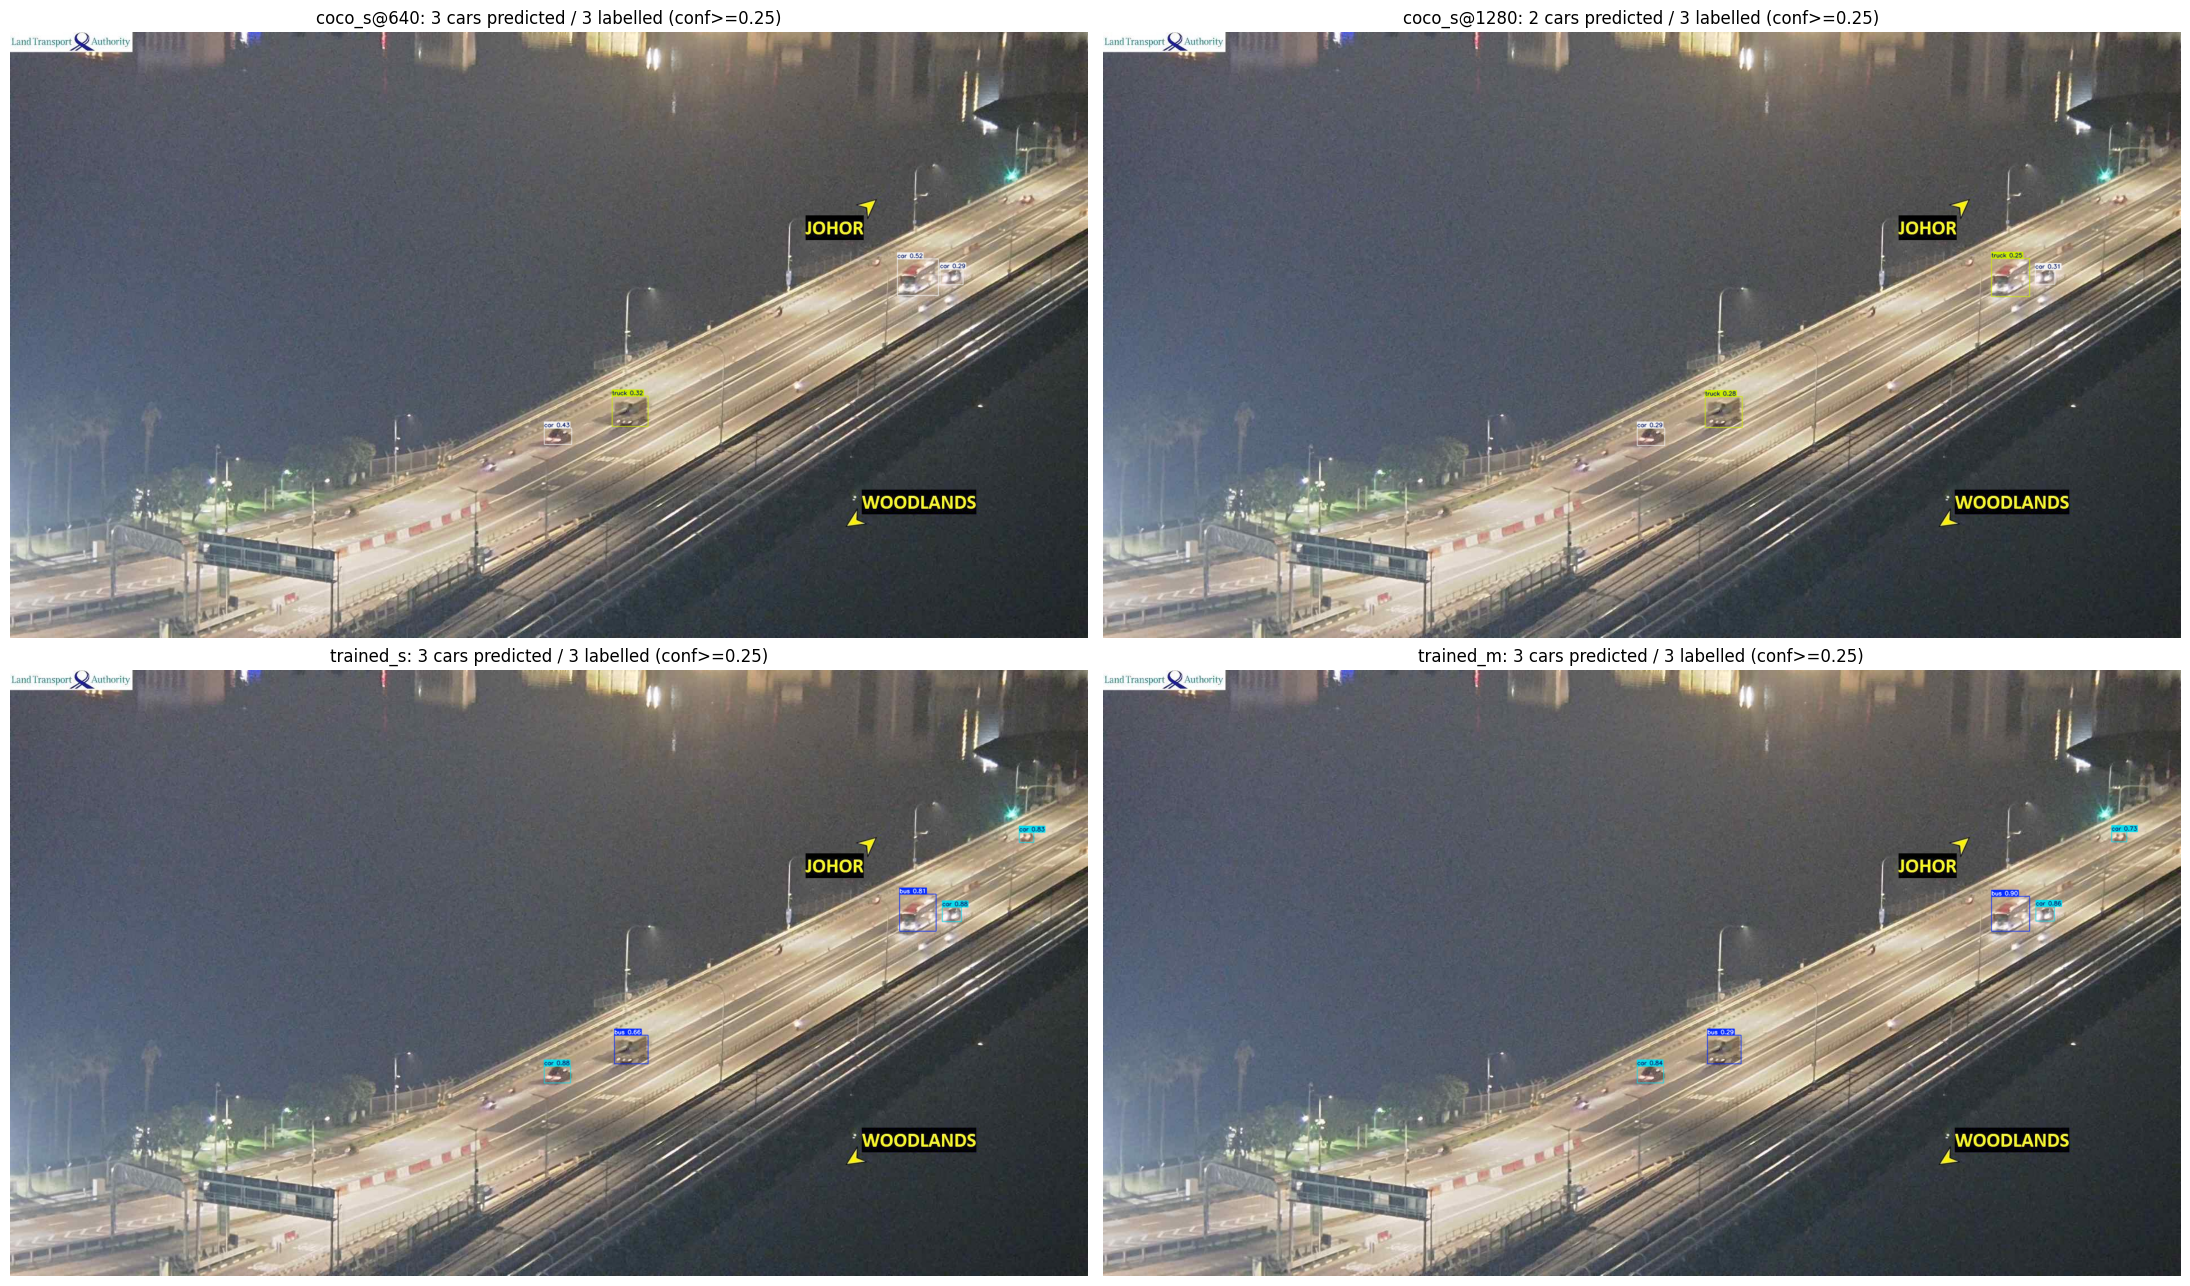

In [ ]:
# ============================================================
# STANDALONE: off-the-shelf YOLO26s (COCO weights, no fine-tuning)
# vs your trained s and m. Works on a FRESH runtime: no need to rerun
# the s-vs-m cell. Nothing is trained here.
#
# Needs: GPU runtime, Colab secret ROBOFLOW_API_KEY (or you'll be prompted),
# and the trained weights already on Drive from the earlier run.
# ============================================================
!pip install -q -U ultralytics roboflow

import os, glob, yaml, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
from roboflow import Roboflow

# ---------------- CONFIG (same as the s-vs-m cell) ----------------
WORKSPACE   = "chads-workspace-t3qcz"
PROJECT     = "vehicle-detection-proejct"
VERSION     = 6
IMGSZ       = 1280
FOCUS_CLASS = "car"
CONF_SWEEP  = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
IOU_MATCH   = 0.5
RUN_DIR     = "/content/drive/MyDrive/swiftborder_runs"
MODELS = {
    "yolo26s": f"{RUN_DIR}/v{VERSION}_yolo26s_boxfix/weights/best.pt",
    "yolo26m": f"{RUN_DIR}/v{VERSION}_yolo26m_boxfix/weights/best.pt",
}

# ---------------- DRIVE + KEY ----------------
from google.colab import drive
drive.mount("/content/drive")
for k, p in MODELS.items():
    assert os.path.exists(p), f"{k} weights not found at {p}"
try:
    from google.colab import userdata
    API_KEY = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    API_KEY = None
if not API_KEY:
    from getpass import getpass
    API_KEY = getpass("Roboflow API key: ")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE (will be slow)")

# ---------------- DATASET (download only, seconds) ----------------
ds = Roboflow(api_key=API_KEY).workspace(WORKSPACE).project(PROJECT).version(VERSION).download(
    "yolov8", location=f"/content/dataset_v{VERSION}", overwrite=False)
with open(os.path.join(ds.location, "data.yaml")) as f:
    names = yaml.safe_load(f)["names"]
CLASS_NAMES = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
FOCUS = CLASS_NAMES.index(FOCUS_CLASS)
SPLIT_DIRS = {s: os.path.join(ds.location, s) for s in ["train", "valid", "test"]
              if os.path.isdir(os.path.join(ds.location, s, "images"))}

def list_images(split_dir):
    exts = ("*.jpg", "*.jpeg", "*.png")
    return sorted(p for e in exts for p in glob.glob(os.path.join(split_dir, "images", e)))

def label_path(img_path):
    d = os.path.dirname(os.path.dirname(img_path))
    return os.path.join(d, "labels", os.path.splitext(os.path.basename(img_path))[0] + ".txt")

def load_gt(img_path):
    """Boxes and polygons both handled; polygons become their enclosing box."""
    p = label_path(img_path)
    cls, boxes = [], []
    if os.path.exists(p):
        with open(p) as f:
            for line in f:
                v = line.split()
                if len(v) < 5:
                    continue
                c, nums = int(float(v[0])), np.array(v[1:], float)
                if len(nums) == 4:
                    cx, cy, w, h = nums
                    boxes.append([cx - w/2, cy - h/2, cx + w/2, cy + h/2])
                else:
                    xs, ys = nums[0::2], nums[1::2]
                    boxes.append([xs.min(), ys.min(), xs.max(), ys.max()])
                cls.append(c)
    if not cls:
        return np.zeros(0, int), np.zeros((0, 4))
    return np.array(cls, int), np.array(boxes, float)

def box_iou(a, b):
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(rb - lt, 0, None)
    inter = wh[..., 0] * wh[..., 1]
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def greedy_tp(gt_box, p_box, p_conf):
    order = np.argsort(-p_conf)
    tp = np.zeros(len(order), bool)
    if len(gt_box) and len(order):
        ious = box_iou(p_box[order], gt_box)
        used = np.zeros(len(gt_box), bool)
        for i in range(len(order)):
            cand = np.where(~used & (ious[i] >= IOU_MATCH))[0]
            if cand.size:
                j = cand[np.argmax(ious[i, cand])]
                used[j] = tp[i] = True
    return p_conf[order], tp

def sweep(recs, cls=None):
    confs, tps, per_img, n_gt = [], [], [], 0
    for r in recs:
        gm = np.ones(len(r["gt_cls"]), bool) if cls is None else r["gt_cls"] == cls
        pm = r["p_cls"] >= 0 if cls is None else r["p_cls"] == cls
        c, tp = greedy_tp(r["gt_box"][gm], r["p_box"][pm], r["p_conf"][pm])
        confs.append(c); tps.append(tp); per_img.append((gm.sum(), c)); n_gt += gm.sum()
    confs, tps = np.concatenate(confs), np.concatenate(tps)
    gt_counts = np.array([g for g, _ in per_img])
    rows = []
    for t in CONF_SWEEP:
        k = confs >= t
        TP, P = tps[k].sum(), k.sum()
        prec = TP / P if P else np.nan
        rec = TP / n_gt if n_gt else np.nan
        pred_counts = np.array([(c >= t).sum() for _, c in per_img])
        rows.append({"conf": t, "recall": rec, "precision": prec,
                     "F1": 2 * prec * rec / (prec + rec) if prec + rec else np.nan,
                     "count_MAE/img": np.abs(pred_counts - gt_counts).mean(),
                     "count_ratio": pred_counts.sum() / max(gt_counts.sum(), 1)})
    return pd.DataFrame(rows).set_index("conf")

# ============================================================
# BASELINE COMPARISON
# ============================================================
_trapz = getattr(np, "trapezoid", None) or np.trapz
AP_CONF = 0.001          # near-zero threshold so AP sees the full PR curve
REPORT_CONF = 0.25       # fixed threshold for the side-by-side row
EVAL_SPLITS = [s for s in ["valid", "test"] if s in SPLIT_DIRS]

# COCO weights were trained at 640, so test the baseline at both 640 and 1280.
RUNS = {
    "coco_s@640":  ("yolo26s.pt", 640),
    "coco_s@1280": ("yolo26s.pt", 1280),
    "trained_s":   (MODELS["yolo26s"], IMGSZ),
    "trained_m":   (MODELS["yolo26m"], IMGSZ),
}


def collect_full(weights, imgsz, split_dir):
    """Predict at near-zero confidence, map classes by name, drop unmapped."""
    model = YOLO(weights)
    name_to_ds = {n: i for i, n in enumerate(CLASS_NAMES)}
    cmap = np.array([name_to_ds.get(model.names[i], -1) for i in range(len(model.names))])
    recs, speeds = [], []
    for r in model.predict(source=list_images(split_dir), conf=AP_CONF, imgsz=imgsz,
                           stream=True, verbose=False, max_det=300):
        gc, gb = load_gt(r.path)
        pc = cmap[r.boxes.cls.cpu().numpy().astype(int)]
        keep = pc >= 0
        recs.append({"gt_cls": gc, "gt_box": gb, "p_cls": pc[keep],
                     "p_box": r.boxes.xyxyn.cpu().numpy()[keep],
                     "p_conf": r.boxes.conf.cpu().numpy()[keep]})
        speeds.append(r.speed["inference"])
    return recs, float(np.mean(speeds)), model


def ap50(recs, cls=None):
    """AP at IoU 0.5, 101-point interpolation (same method as Ultralytics).
    cls=None means class-agnostic (any vehicle)."""
    confs, tps, n_gt = [], [], 0
    for r in recs:
        gm = np.ones(len(r["gt_cls"]), bool) if cls is None else r["gt_cls"] == cls
        pm = np.ones(len(r["p_cls"]), bool) if cls is None else r["p_cls"] == cls
        c, tp = greedy_tp(r["gt_box"][gm], r["p_box"][pm], r["p_conf"][pm])
        confs.append(c); tps.append(tp); n_gt += gm.sum()
    if n_gt == 0:
        return np.nan
    confs, tps = np.concatenate(confs), np.concatenate(tps)
    tps = tps[np.argsort(-confs)]
    ctp, cfp = np.cumsum(tps), np.cumsum(~tps)
    rec = ctp / n_gt
    prec = ctp / np.maximum(ctp + cfp, 1)
    mrec = np.concatenate([[0.0], rec, [1.0]])
    mpre = np.concatenate([[1.0], prec, [0.0]])
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))   # precision envelope
    x = np.linspace(0, 1, 101)
    return float(_trapz(np.interp(x, mrec, mpre), x))


pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 200)
all_recs, models_loaded, summary_rows = {}, {}, []

for split in EVAL_SPLITS:
    for tag, (w, sz) in RUNS.items():
        recs, ms, model = collect_full(w, sz, SPLIT_DIRS[split])
        all_recs[(split, tag)] = recs
        models_loaded[tag] = (model, sz)

        ap = {c: ap50(recs, CLASS_NAMES.index(c)) for c in CLASS_NAMES}
        car_sw = sweep(recs, FOCUS)          # thresholds from CONF_SWEEP
        agn_sw = sweep(recs, None)
        best_t = car_sw["count_MAE/img"].idxmin()
        fixed, best = car_sw.loc[REPORT_CONF], car_sw.loc[best_t]

        summary_rows.append({
            "split": split, "model": tag, "ms/img": round(ms, 1),
            **{f"AP50 {c}": ap[c] for c in CLASS_NAMES},
            "mAP50": np.nanmean(list(ap.values())),
            "AP50 any-vehicle": ap50(recs, None),
            f"car R@{REPORT_CONF}": fixed["recall"],
            f"car P@{REPORT_CONF}": fixed["precision"],
            f"count ratio@{REPORT_CONF}": fixed["count_ratio"],
            "best conf (car count)": best_t,
            "car R@best": best["recall"],
            "car P@best": best["precision"],
            "car MAE/img@best": best["count_MAE/img"],
            "count ratio@best": best["count_ratio"],
        })

        if tag.startswith("coco"):
            print(f"\n=== {tag} | {split} | {ms:.1f} ms/img ===")
            print("[car only]");  print(car_sw.to_string())
            print("[any vehicle]"); print(agn_sw.to_string())

summary = pd.DataFrame(summary_rows).set_index(["split", "model"])
ap_cols = [f"AP50 {c}" for c in CLASS_NAMES] + ["mAP50", "AP50 any-vehicle", "ms/img"]
op_cols = [c for c in summary.columns if c not in ap_cols]

print("\n" + "=" * 90 + "\nACCURACY (AP50, threshold-free)\n" + "=" * 90)
print(summary[ap_cols].to_string())
print("\n" + "=" * 90 + "\nOPERATING POINT (car counting)\n" + "=" * 90)
print(summary[op_cols].to_string())

# Gain from fine-tuning, on the split that never influenced training
split = "test" if "test" in EVAL_SPLITS else "valid"
base = summary.loc[(split, "coco_s@1280")]
for tag in ["trained_s", "trained_m"]:
    row = summary.loc[(split, tag)]
    print(f"\n{tag} vs coco_s@1280 ({split}): "
          f"car AP50 {100 * (row['AP50 car'] - base['AP50 car']):+.1f} pts, "
          f"mAP50 {100 * (row['mAP50'] - base['mAP50']):+.1f} pts, "
          f"car recall@best {100 * (row['car R@best'] - base['car R@best']):+.1f} pts, "
          f"car MAE/img {row['car MAE/img@best'] - base['car MAE/img@best']:+.1f} cars")

# ---------------- VISUAL: same test image, all four models ----------------
img_path = list_images(SPLIT_DIRS[split])[0]
gt_cls, _ = load_gt(img_path)
fig, axes = plt.subplots(2, 2, figsize=(22, 13))
for ax, (tag, (model, sz)) in zip(axes.ravel(), models_loaded.items()):
    keep_ids = [k for k, v in model.names.items() if v in CLASS_NAMES]
    r = model.predict(img_path, conf=REPORT_CONF, imgsz=sz, classes=keep_ids, verbose=False)[0]
    n_car = sum(model.names[int(c)] == FOCUS_CLASS for c in r.boxes.cls.tolist())
    ax.imshow(r.plot(line_width=1, font_size=8)[..., ::-1])
    ax.set_title(f"{tag}: {n_car} cars predicted / {int((gt_cls == FOCUS).sum())} labelled "
                 f"(conf>={REPORT_CONF})", fontsize=12)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Save each model's annotated predictions on all test images to Drive,
# plus a CSV of predicted vs labelled counts. Works on a fresh runtime.
!pip install -q -U ultralytics roboflow
import os, glob, yaml, pandas as pd
from ultralytics import YOLO
from google.colab import drive
drive.mount("/content/drive")

RUN_DIR = "/content/drive/MyDrive/swiftborder_runs"
OUT_DIR = f"{RUN_DIR}/test_predictions"
DATA = "/content/dataset_v6"
if not os.path.isdir(f"{DATA}/test/images"):          # re-download only if missing
    from roboflow import Roboflow
    from google.colab import userdata
    Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY")).workspace("chads-workspace-t3qcz") \
        .project("vehicle-detection-proejct").version(6).download("yolov8", location=DATA)

names = yaml.safe_load(open(f"{DATA}/data.yaml"))["names"]
CLASS_NAMES = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
CAR = CLASS_NAMES.index("car")

# (weights, image size, confidence): each model at its best car-count threshold
RUNS = {
    "coco_s@640":  ("yolo26s.pt", 640, 0.10),
    "coco_s@1280": ("yolo26s.pt", 1280, 0.10),
    "trained_s":   (f"{RUN_DIR}/v6_yolo26s_boxfix/weights/best.pt", 1280, 0.30),
    "trained_m":   (f"{RUN_DIR}/v6_yolo26m_boxfix/weights/best.pt", 1280, 0.25),
}
images = sorted(glob.glob(f"{DATA}/test/images/*.jpg"))

def labelled_cars(img):
    lbl = img.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    return sum(1 for l in open(lbl) if l.strip() and int(float(l.split()[0])) == CAR)

rows = []
for tag, (w, sz, conf) in RUNS.items():
    model = YOLO(w)
    keep = [k for k, v in model.names.items() if v in CLASS_NAMES]   # COCO: only car/bus/truck
    os.makedirs(f"{OUT_DIR}/{tag}", exist_ok=True)
    for r in model.predict(images, imgsz=sz, conf=conf, classes=keep, stream=True, verbose=False):
        name = os.path.basename(r.path)
        r.save(filename=f"{OUT_DIR}/{tag}/{name}", line_width=1, font_size=8)
        pred = [model.names[int(c)] for c in r.boxes.cls.tolist()]
        rows.append({"model": tag, "image": name, "conf": conf,
                     "pred_cars": pred.count("car"), "labelled_cars": labelled_cars(r.path),
                     "pred_vehicles": len(pred)})
    print(f"{tag}: saved {len(images)} images to {OUT_DIR}/{tag}")

df = pd.DataFrame(rows)
df["car_error"] = df.pred_cars - df.labelled_cars
df.to_csv(f"{OUT_DIR}/test_counts.csv", index=False)
print(df.pivot(index="image", columns="model", values="car_error").to_string())
print("\nMean absolute car error per image:\n", df.groupby("model").car_error.apply(lambda s: s.abs().mean()).round(2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
coco_s@640: saved 15 images to /content/drive/MyDrive/swiftborder_runs/test_predictions/coco_s@640
coco_s@1280: saved 15 images to /content/drive/MyDrive/swiftborder_runs/test_predictions/coco_s@1280
trained_s: saved 15 images to /content/drive/MyDrive/swiftborder_runs/test_predictions/trained_s
trained_m: saved 15 images to /content/drive/MyDrive/swiftborder_runs/test_predictions/trained_m
model                                                                                          coco_s@1280  coco_s@640  trained_m  trained_s
image                                                                                                                                       
2701_20250701T031541_jpg.rf.305d8ff6133a3042f867f23ec741ae18.jpg                                         0           2          0          0
2701_20250701T171615_jpg.rf.2c614559e4c9ff55ed03ec2de9

In [ ]:
# ============================================================
# FULL COMPARISON (replaces the baseline cell and the save-predictions cell)
#   roboflow_v6   Roboflow-hosted YOLO26s v6 (your augmentation recipe, via API)
#   coco_s@640    stock COCO YOLO26s, no fine-tuning
#   coco_s@1280   stock COCO YOLO26s, no fine-tuning
#   trained_s     local fine-tuned YOLO26s (frozen backbone)
#   trained_m     local fine-tuned YOLO26m (frozen backbone)
# Same images, same box matching, same metrics for all five.
# Saves annotated test images per model + ground truth + counts CSV to Drive.
#
# Roboflow cost: one API call per image (30 images), cached on Drive, so
# reruns spend nothing. Works on a fresh runtime; GPU recommended.
# ============================================================
!pip install -q -U ultralytics roboflow

import os, glob, json, base64, time, yaml, requests
import numpy as np, pandas as pd
from PIL import Image, ImageDraw
from ultralytics import YOLO
from google.colab import drive
drive.mount("/content/drive")

# ---------------- CONFIG ----------------
RUN_DIR     = "/content/drive/MyDrive/swiftborder_runs"
OUT_DIR     = f"{RUN_DIR}/test_predictions"
DATA        = "/content/dataset_v6"
RF_MODEL_ID = "vehicle-detection-proejct/6"           # project/version of the hosted model
RF_URL      = "https://serverless.roboflow.com"
RF_CACHE    = f"{RUN_DIR}/roboflow_v6_cache"         # raw API responses, reused on rerun
RF_QUERY_CONF = 0.01                                  # near-zero so AP sees the full curve
AP_CONF     = 0.001
IOU_MATCH   = 0.5
CONF_SWEEP  = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
REPORT_CONF = 0.25
FOCUS_CLASS = "car"

RUNS = {  # tag: (weights or "roboflow", image size)
    "coco_s@640":  ("yolo26s.pt", 640),
    "coco_s@1280": ("yolo26s.pt", 1280),
    "roboflow_v6": ("roboflow", None),
    "trained_s":   (f"{RUN_DIR}/v6_yolo26s_boxfix/weights/best.pt", 1280),
    "trained_m":   (f"{RUN_DIR}/v6_yolo26m_boxfix/weights/best.pt", 1280),
}

try:
    from google.colab import userdata
    API_KEY = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    API_KEY = None
if not API_KEY:
    from getpass import getpass
    API_KEY = getpass("Roboflow API key: ")

# ---------------- DATASET ----------------
if not os.path.isdir(f"{DATA}/test/images"):
    from roboflow import Roboflow
    Roboflow(api_key=API_KEY).workspace("chads-workspace-t3qcz") \
        .project("vehicle-detection-proejct").version(6).download("yolov8", location=DATA)
names = yaml.safe_load(open(f"{DATA}/data.yaml"))["names"]
CLASS_NAMES = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
FOCUS = CLASS_NAMES.index(FOCUS_CLASS)
NAME_TO_DS = {n: i for i, n in enumerate(CLASS_NAMES)}
SPLITS = [s for s in ["valid", "test"] if os.path.isdir(f"{DATA}/{s}/images")]

def list_images(split):
    return sorted(p for e in ("*.jpg", "*.jpeg", "*.png") for p in glob.glob(f"{DATA}/{split}/images/{e}"))

def load_gt(img_path):
    """Boxes and polygons both handled; polygons become their enclosing box."""
    lbl = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    cls, boxes = [], []
    if os.path.exists(lbl):
        for line in open(lbl):
            v = line.split()
            if len(v) < 5:
                continue
            c, nums = int(float(v[0])), np.array(v[1:], float)
            if len(nums) == 4:
                cx, cy, w, h = nums
                boxes.append([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])
            else:
                xs, ys = nums[0::2], nums[1::2]
                boxes.append([xs.min(), ys.min(), xs.max(), ys.max()])
            cls.append(c)
    if not cls:
        return np.zeros(0, int), np.zeros((0, 4))
    return np.array(cls, int), np.array(boxes, float)

# ---------------- MATCHING + METRICS ----------------
def box_iou(a, b):
    lt = np.maximum(a[:, None, :2], b[None, :, :2]); rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(rb - lt, 0, None); inter = wh[..., 0] * wh[..., 1]
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def greedy_tp(gt_box, p_box, p_conf):
    order = np.argsort(-p_conf); tp = np.zeros(len(order), bool)
    if len(gt_box) and len(order):
        ious = box_iou(p_box[order], gt_box); used = np.zeros(len(gt_box), bool)
        for i in range(len(order)):
            cand = np.where(~used & (ious[i] >= IOU_MATCH))[0]
            if cand.size:
                j = cand[np.argmax(ious[i, cand])]; used[j] = tp[i] = True
    return p_conf[order], tp

def _masks(r, cls):
    gm = np.ones(len(r["gt_cls"]), bool) if cls is None else r["gt_cls"] == cls
    pm = np.ones(len(r["p_cls"]), bool) if cls is None else r["p_cls"] == cls
    return gm, pm

def sweep(recs, cls=None):
    confs, tps, per_img, n_gt = [], [], [], 0
    for r in recs:
        gm, pm = _masks(r, cls)
        c, tp = greedy_tp(r["gt_box"][gm], r["p_box"][pm], r["p_conf"][pm])
        confs.append(c); tps.append(tp); per_img.append((gm.sum(), c)); n_gt += gm.sum()
    confs, tps = np.concatenate(confs), np.concatenate(tps)
    gt_counts = np.array([g for g, _ in per_img]); rows = []
    for t in CONF_SWEEP:
        k = confs >= t; TP, P = tps[k].sum(), k.sum()
        prec = TP / P if P else np.nan; rec = TP / n_gt if n_gt else np.nan
        pred_counts = np.array([(c >= t).sum() for _, c in per_img])
        rows.append({"conf": t, "recall": rec, "precision": prec,
                     "F1": 2 * prec * rec / (prec + rec) if prec + rec else np.nan,
                     "count_MAE/img": np.abs(pred_counts - gt_counts).mean(),
                     "count_ratio": pred_counts.sum() / max(gt_counts.sum(), 1)})
    return pd.DataFrame(rows).set_index("conf")

_trapz = getattr(np, "trapezoid", None) or np.trapz
def ap50(recs, cls=None):
    confs, tps, n_gt = [], [], 0
    for r in recs:
        gm, pm = _masks(r, cls)
        c, tp = greedy_tp(r["gt_box"][gm], r["p_box"][pm], r["p_conf"][pm])
        confs.append(c); tps.append(tp); n_gt += gm.sum()
    if n_gt == 0:
        return np.nan
    tps = np.concatenate(tps)[np.argsort(-np.concatenate(confs))]
    ctp, cfp = np.cumsum(tps), np.cumsum(~tps)
    mrec = np.concatenate([[0.0], ctp / n_gt, [1.0]])
    mpre = np.concatenate([[1.0], ctp / np.maximum(ctp + cfp, 1), [0.0]])
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    return float(_trapz(np.interp(x, mrec, mpre), x))

# ---------------- PREDICTORS ----------------
def collect_yolo(weights, imgsz, split):
    model = YOLO(weights)
    cmap = np.array([NAME_TO_DS.get(model.names[i], -1) for i in range(len(model.names))])
    recs, ms = [], []
    for r in model.predict(list_images(split), conf=AP_CONF, imgsz=imgsz,
                           stream=True, verbose=False, max_det=300):
        gc, gb = load_gt(r.path); pc = cmap[r.boxes.cls.cpu().numpy().astype(int)]; keep = pc >= 0
        recs.append({"path": r.path, "gt_cls": gc, "gt_box": gb, "p_cls": pc[keep],
                     "p_box": r.boxes.xyxyn.cpu().numpy()[keep],
                     "p_conf": r.boxes.conf.cpu().numpy()[keep]})
        ms.append(r.speed["inference"])
    return recs, f"{np.mean(ms):.1f} (GPU)"

def rf_infer(img_path, split):
    os.makedirs(RF_CACHE, exist_ok=True)
    cache = f"{RF_CACHE}/{split}_{os.path.basename(img_path)}.json"
    if os.path.exists(cache):
        return json.load(open(cache)), None
    b64 = base64.b64encode(open(img_path, "rb").read()).decode()
    t0 = time.perf_counter()
    resp = requests.post(f"{RF_URL}/{RF_MODEL_ID}",
                         params={"api_key": API_KEY, "confidence": RF_QUERY_CONF, "overlap": 0.5},
                         data=b64, headers={"Content-Type": "application/x-www-form-urlencoded"},
                         timeout=120)
    if resp.status_code != 200:
        raise RuntimeError(f"Roboflow API {resp.status_code}: {resp.text[:300]}\n"
                           f"Check RF_MODEL_ID (currently '{RF_MODEL_ID}').")
    out = resp.json()
    json.dump(out, open(cache, "w"))
    return out, (time.perf_counter() - t0) * 1000

def collect_roboflow(split):
    recs, ms = [], []
    for p in list_images(split):
        out, latency = rf_infer(p, split)
        if latency is not None:
            ms.append(latency)
        W, H = Image.open(p).size
        preds = out.get("predictions", [])
        pc = np.array([NAME_TO_DS.get(d["class"], -1) for d in preds], int)
        pb = np.array([[(d["x"] - d["width"] / 2) / W, (d["y"] - d["height"] / 2) / H,
                        (d["x"] + d["width"] / 2) / W, (d["y"] + d["height"] / 2) / H]
                       for d in preds], float).reshape(-1, 4)
        pf = np.array([d["confidence"] for d in preds], float)
        keep = pc >= 0
        gc, gb = load_gt(p)
        recs.append({"path": p, "gt_cls": gc, "gt_box": gb,
                     "p_cls": pc[keep], "p_box": pb[keep], "p_conf": pf[keep]})
    n = sum(len(r["p_conf"]) for r in recs)
    low = min((r["p_conf"].min() for r in recs if len(r["p_conf"])), default=float("nan"))
    print(f"  roboflow_v6 {split}: {n} boxes, lowest confidence {low:.3f} "
          f"(should be well under 0.10 for a full PR curve)")
    return recs, (f"{np.mean(ms):.0f} (API round trip)" if ms else "cached")

# ---------------- EVALUATE ----------------
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 220)
all_recs, rows = {}, []
for split in SPLITS:
    for tag, (w, sz) in RUNS.items():
        recs, speed = collect_roboflow(split) if w == "roboflow" else collect_yolo(w, sz, split)
        all_recs[(split, tag)] = recs
        ap = {c: ap50(recs, CLASS_NAMES.index(c)) for c in CLASS_NAMES}
        car_sw = sweep(recs, FOCUS)
        best_t = car_sw["count_MAE/img"].idxmin()
        fixed, best = car_sw.loc[REPORT_CONF], car_sw.loc[best_t]
        rows.append({"split": split, "model": tag, "ms/img": speed,
                     **{f"AP50 {c}": ap[c] for c in CLASS_NAMES},
                     "mAP50": np.nanmean(list(ap.values())), "AP50 any-vehicle": ap50(recs, None),
                     f"car R@{REPORT_CONF}": fixed["recall"], f"car P@{REPORT_CONF}": fixed["precision"],
                     f"count ratio@{REPORT_CONF}": fixed["count_ratio"],
                     "best conf (car count)": best_t, "car R@best": best["recall"],
                     "car P@best": best["precision"], "car MAE/img@best": best["count_MAE/img"],
                     "count ratio@best": best["count_ratio"]})
        if tag == "roboflow_v6":
            print(f"\n=== roboflow_v6 | {split} ===")
            print("[car only]"); print(car_sw.to_string())
            print("[any vehicle]"); print(sweep(recs, None).to_string())

summary = pd.DataFrame(rows).set_index(["split", "model"])
ap_cols = [f"AP50 {c}" for c in CLASS_NAMES] + ["mAP50", "AP50 any-vehicle", "ms/img"]
op_cols = [c for c in summary.columns if c not in ap_cols]
print("\n" + "=" * 100 + "\nACCURACY (AP50, threshold-free)\n" + "=" * 100)
print(summary[ap_cols].to_string())
print("\n" + "=" * 100 + "\nOPERATING POINT (car counting)\n" + "=" * 100)
print(summary[op_cols].to_string())
summary.to_csv(f"{RUN_DIR}/full_comparison_summary.csv")

split = "test" if "test" in SPLITS else "valid"
rf = summary.loc[(split, "roboflow_v6")]
for tag in ["trained_s", "trained_m"]:
    row = summary.loc[(split, tag)]
    print(f"\n{tag} vs roboflow_v6 ({split}): "
          f"car AP50 {100 * (row['AP50 car'] - rf['AP50 car']):+.1f} pts, "
          f"mAP50 {100 * (row['mAP50'] - rf['mAP50']):+.1f} pts, "
          f"car recall@best {100 * (row['car R@best'] - rf['car R@best']):+.1f} pts, "
          f"car MAE/img {row['car MAE/img@best'] - rf['car MAE/img@best']:+.1f} cars")

# ---------------- SAVE ANNOTATED TEST IMAGES ----------------
COLORS = {"car": (0, 200, 0), "bus": (255, 165, 0), "truck": (220, 40, 40)}

def draw(img_path, boxes, cls, confs, out_path, title):
    im = Image.open(img_path).convert("RGB"); W, H = im.size; d = ImageDraw.Draw(im)
    for (x1, y1, x2, y2), c, s in zip(boxes, cls, confs):
        col = COLORS.get(CLASS_NAMES[c], (0, 160, 255))
        d.rectangle([x1 * W, y1 * H, x2 * W, y2 * H], outline=col, width=2)
        if s is not None:
            d.text((x1 * W + 2, max(y1 * H - 11, 0)), f"{s:.2f}", fill=col)
    d.rectangle([0, 0, W, 28], fill=(0, 0, 0)); d.text((8, 8), title, fill=(255, 255, 255))
    im.save(out_path, quality=90)

count_rows = []
os.makedirs(f"{OUT_DIR}/ground_truth", exist_ok=True)
for r in all_recs[(split, "trained_s")]:
    n_car = int((r["gt_cls"] == FOCUS).sum())
    draw(r["path"], r["gt_box"], r["gt_cls"], [None] * len(r["gt_cls"]),
         f"{OUT_DIR}/ground_truth/{os.path.basename(r['path'])}",
         f"GROUND TRUTH: {n_car} cars, {len(r['gt_cls'])} vehicles")

for tag in RUNS:
    t = float(summary.loc[(split, tag), "best conf (car count)"])
    os.makedirs(f"{OUT_DIR}/{tag}", exist_ok=True)
    for r in all_recs[(split, tag)]:
        k = r["p_conf"] >= t
        pc, n_lab = r["p_cls"][k], int((r["gt_cls"] == FOCUS).sum())
        n_pred = int((pc == FOCUS).sum()); name = os.path.basename(r["path"])
        draw(r["path"], r["p_box"][k], pc, r["p_conf"][k], f"{OUT_DIR}/{tag}/{name}",
             f"{tag} @ conf {t:.2f}: {n_pred} cars predicted / {n_lab} labelled")
        count_rows.append({"model": tag, "image": name, "conf": t, "pred_cars": n_pred,
                           "labelled_cars": n_lab, "pred_vehicles": int(k.sum()),
                           "car_error": n_pred - n_lab})
    print(f"{tag}: saved {len(all_recs[(split, tag)])} images to {OUT_DIR}/{tag}")

counts = pd.DataFrame(count_rows)
counts.to_csv(f"{OUT_DIR}/test_counts.csv", index=False)
print("\nCar count error per image (predicted minus labelled):")
print(counts.pivot(index="image", columns="model", values="car_error")[list(RUNS)].to_string())
print("\nMean absolute car error per image:")
print(counts.groupby("model").car_error.apply(lambda s: s.abs().mean()).reindex(list(RUNS)).round(2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  roboflow_v6 valid: 1454 boxes, lowest confidence 0.010 (should be well under 0.10 for a full PR curve)

=== roboflow_v6 | valid ===
[car only]
       recall  precision    F1  count_MAE/img  count_ratio
conf                                                      
0.100   0.789      0.611 0.689         10.467        1.290
0.150   0.755      0.664 0.706          7.533        1.137
0.200   0.732      0.692 0.711          6.333        1.057
0.250   0.721      0.718 0.719          5.600        1.004
0.300   0.700      0.761 0.729          4.933        0.920
0.400   0.662      0.811 0.729          7.533        0.816
0.500   0.632      0.845 0.723          8.600        0.748
[any vehicle]
       recall  precision    F1  count_MAE/img  count_ratio
conf                                                      
0.100   0.754      0.617 0.678         12.133        1.222
0.15